# Jogo patológico e outros diagnósticos (comorbidade)

Com que outros transtornos o jogo patológico (**F63.0**) aparece nos CAPS, e isso mudou durante a alta de 2024–2026?

**Por que importa.** Se os novos pacientes chegam com jogo patológico **junto** com depressão, ansiedade ou álcool, a
rede precisa tratar várias coisas ao mesmo tempo. Se chegam com o jogo como **único** problema, o perfil é outro: gente
que talvez nunca tivesse procurado o CAPS por outro motivo. Isso também conversa com a dúvida central dos outros
notebooks: uma alta de casos "só jogo" combina com **demanda nova**; uma alta puxada por quem já tinha outro
diagnóstico combina com **reclassificação**.

**Dados:** `sia_f63_registros` e `sia_f63_historico` (ver `f63_pacientes.ipynb`), já pseudonimizados.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
import polars as pl

from src.config import pasta

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", "{:.1f}".format)
MIN_CELULA = 5
CORTE = "202606"

## Decisões

**Unidade: paciente-ano.** Para cada pessoa com F63.0 num ano, juntamos **todos os outros diagnósticos registrados para
ela no CAPS naquele ano**:
- o CID **associado** das RAAS em que o F63.0 é o principal;
- o CID **principal** das RAAS em que o F63.0 é o associado;
- o CID **principal** de qualquer outra RAAS dela no mesmo ano (do histórico).

Assim, uma pessoa com depressão tratada em março e jogo em agosto conta como comorbidade, mesmo que os dois nunca
apareçam na mesma RAAS. Uma pessoa pode ter vários outros diagnósticos, então os percentuais **não somam 100%**.

**Grupos de CID:**
| Grupo | CID-10 |
|---|---|
| Humor (depressão, bipolar) | F30–F39 |
| Ansiedade | F40–F48 |
| Álcool | F10 |
| Outras substâncias (cocaína, crack, múltiplas) | F11–F19 |
| Psicoses | F20–F29 |
| Personalidade e outros transtornos de impulso | F60–F69, exceto F63 |

**Z72.6.** A CID-10 tem um código fora do capítulo F, **Z72.6 "mania de jogo e apostas"**, para registrar o
comportamento sem diagnosticar transtorno. Ele aparece como CID associado em algumas RAAS. Não conta como comorbidade;
contamos à parte.

**Período e supressão.** Jan/2018 a jun/2026 (2026 só até junho). Percentuais calculados sobre menos de 5 pacientes
ficam em branco. 2018–2021 têm poucos pacientes por ano (46–81), então os percentuais desses anos oscilam muito.

In [2]:
filtro = pl.col("cmp").is_between(pl.lit("201801"), pl.lit(CORTE))
reg = pl.read_parquet(pasta("caps") / "sia_f63_registros.parquet").filter(filtro).with_columns(pl.col("cmp").str.slice(0, 4).cast(pl.Int32).alias("ano"))
hist = pl.read_parquet(pasta("caps") / "sia_f63_historico.parquet").filter(filtro).with_columns(pl.col("cmp").str.slice(0, 4).cast(pl.Int32).alias("ano"))

f630 = reg.filter((pl.col("CIDPRI") == "F630") | (pl.col("CIDASSOC") == "F630"))
pac_ano = f630.select("id", "ano").unique()
sexo = f630.group_by("id", "ano").agg(pl.col("SEXOPAC").first())
outros = (pl.concat([
            f630.select("id", "ano", pl.when(pl.col("CIDPRI") == "F630").then(pl.col("CIDASSOC")).otherwise(pl.col("CIDPRI")).alias("cid")),
            hist.select("id", "ano", pl.col("CIDPRI").alias("cid"))])
          .filter(pl.col("cid").is_not_null() & (pl.col("cid") != ""))
          .join(pac_ano, on=["id", "ano"]))
GRUPOS = {"Humor (F30–F39)": r"^F3", "Ansiedade (F40–F48)": r"^F4", "Álcool (F10)": r"^F10", "Outras substâncias (F11–F19)": r"^F1[1-9]",
          "Psicoses (F20–F29)": r"^F2", "Personalidade/impulsos (F60–F69 exc. F63)": r"^F6"}
outros = outros.filter(~pl.col("cid").str.starts_with("F63"))
flags = outros.group_by("id", "ano").agg(
    *[pl.col("cid").str.contains(p).any().alias(g) for g, p in GRUPOS.items()],
    pl.col("cid").str.starts_with("F").any().alias("Algum outro F"),
    pl.col("cid").str.starts_with("Z726").any().alias("Z72.6 (jogo e apostas)"))
base = pac_ano.join(flags, on=["id", "ano"], how="left").fill_null(False).join(sexo, on=["id", "ano"])
print(f"{base.height:,} pacientes-ano com F63.0, {base['ano'].min()}–{base['ano'].max()}")

2,568 pacientes-ano com F63.0, 2018–2026


## 1. Comorbidade por ano

In [3]:
cols = [*GRUPOS, "Algum outro F", "Z72.6 (jogo e apostas)"]
cont = base.group_by("ano").agg(pl.len().alias("pacientes"), *[pl.col(c).sum() for c in cols]).sort("ano")
pct = cont.with_columns([pl.when(pl.col(c) < MIN_CELULA).then(None).otherwise(pl.col(c) / pl.col("pacientes") * 100).alias(c) for c in cols])
pct = pct.with_columns((100 - pl.col("Algum outro F")).alias("Só jogo (nenhum outro F)"))
pct.to_pandas().set_index("ano")

,pacientes,Humor (F30–F39),Ansiedade (F40–F48),Álcool (F10),Outras substâncias (F11–F19),Psicoses (F20–F29),Personalidade/impulsos (F60–F69 exc. F63),Algum outro F,Z72.6 (jogo e apostas),Só jogo (nenhum outro F)
ano,,,,,,,,,,
2018,46,28.3,19.6,10.9,NaN,NaN,15.2,69.6,NaN,30.4
2019,67,19.4,11.9,11.9,NaN,NaN,NaN,49.3,NaN,50.7
2020,63,20.6,7.9,11.1,NaN,NaN,12.7,58.7,NaN,41.3
2021,81,16.0,18.5,6.2,9.9,NaN,9.9,56.8,NaN,43.2
2022,124,10.5,20.2,6.5,5.6,NaN,8.9,54.0,NaN,46.0
2023,159,17.0,12.6,4.4,7.5,3.8,7.5,47.2,NaN,52.8
2024,304,12.2,13.2,6.6,6.6,3.3,3.9,47.0,NaN,53.0
2025,869,14.0,12.2,3.9,10.1,1.6,4.0,42.1,1.3,57.9
2026,855,8.8,8.2,2.9,12.2,1.2,2.5,37.8,NaN,62.2


Text(0.5, 1.0, 'Pacientes com jogo patológico: só jogo × com outros diagnósticos')

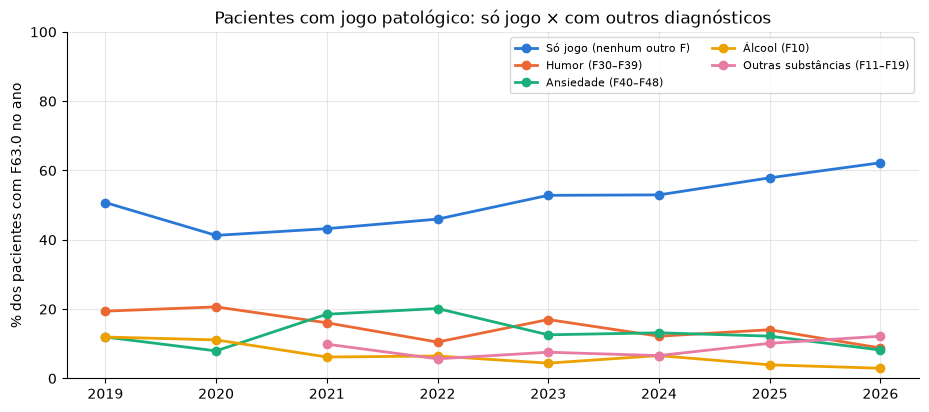

In [4]:
fig, ax = plt.subplots(figsize=(11, 4.5))
d = pct.filter(pl.col("ano") >= 2019)
for c, cor in [("Só jogo (nenhum outro F)", "#2a78d6"), ("Humor (F30–F39)", "#eb6834"), ("Ansiedade (F40–F48)", "#1baf7a"),
               ("Álcool (F10)", "#eda100"), ("Outras substâncias (F11–F19)", "#e87ba4")]:
    ax.plot(d["ano"], d[c], marker="o", lw=2, label=c, color=cor)
ax.set_ylabel("% dos pacientes com F63.0 no ano"); ax.set_ylim(0, 100); ax.legend(fontsize=8, ncol=2)
ax.set_title("Pacientes com jogo patológico: só jogo × com outros diagnósticos")

## 2. Por sexo, no período da alta (2024–2026)

In [5]:
alta = base.filter(pl.col("ano") >= 2024)
cs = alta.group_by("SEXOPAC").agg(pl.len().alias("pacientes_ano"), *[pl.col(c).sum() for c in cols])
cs = cs.with_columns([pl.when(pl.col(c) < MIN_CELULA).then(None).otherwise(pl.col(c) / pl.col("pacientes_ano") * 100).alias(c) for c in cols])
cs = cs.with_columns((100 - pl.col("Algum outro F")).alias("Só jogo (nenhum outro F)"))
cs.to_pandas().set_index("SEXOPAC").T

SEXOPAC,M,F
pacientes_ano,1115.0,913.0
Humor (F30–F39),8.0,15.9
Ansiedade (F40–F48),7.9,14.0
Álcool (F10),4.5,3.2
Outras substâncias (F11–F19),14.3,5.7
Psicoses (F20–F29),1.9,1.4
Personalidade/impulsos (F60–F69 exc. F63),2.1,4.9
Algum outro F,39.7,42.6
Z72.6 (jogo e apostas),0.8,1.1
Só jogo (nenhum outro F),60.3,57.4


## Leitura

**1. A alta é puxada por gente que chega com o jogo como único problema.** Em 2022, 46% dos pacientes com F63.0 não
tinham nenhum outro diagnóstico psiquiátrico registrado no CAPS no ano. Em 2025 eram **58%**. A fração com algum
outro transtorno caiu de 54% para 42%. Isso reforça o achado do `f63_pacientes.ipynb` (a maioria é nova no CAPS): o
perfil que mais cresce é o de pessoas que chegam ao CAPS **pelo jogo**, não pacientes antigos com o jogo acrescentado.

⚠ 2026 vai só até junho. Com menos meses no ano, há menos chances de registrar um segundo diagnóstico, então a queda
para 38% em 2026 é em parte mecânica. **2025 é o último ano comparável.**

**2. As comorbidades mais comuns são depressão e ansiedade (cada uma em ~12–14% em 2025), e o uso de outras substâncias
está subindo.** Cocaína, crack e uso de múltiplas drogas (F11–F19) passaram de ~6% (2022) para ~10% (2025). Álcool ficou
abaixo de 5%. Em 2018–2021, com 46–81 pacientes por ano, os percentuais oscilam demais para comparar.

**3. Homens e mulheres chegam com problemas diferentes (2024–2026):**
- **mulheres:** o dobro de depressão (16% × 8%) e de ansiedade (14% × 8%) associadas;
- **homens:** mais que o dobro de outras substâncias (14% × 6%);
- nos dois sexos, perto de 60% chegam só com o jogo.

O padrão por sexo repete o que se vê em saúde mental em geral (mulheres com mais transtornos de humor e ansiedade,
homens com mais uso de substâncias), agora entre pessoas com problema de jogo.

**4. O Z72.6 ("mania de jogo e apostas") quase não é usado:** cerca de 1% dos pacientes-ano. Os profissionais registram
o problema como transtorno (F63.0), não como comportamento de risco.

**Implicações para a rede:** a maior parte dos novos pacientes precisa de cuidado específico para jogo, não do
tratamento de um transtorno já conhecido. E uma fração crescente de homens chega com jogo **e** cocaína/crack,
combinação que tende a ser atendida nos CAPS AD (álcool e drogas). Ver qual tipo de CAPS atende esses pacientes exige
uma nova extração com o código do estabelecimento.